In [11]:
# Imports and globals
%load_ext autoreload
%matplotlib ipympl
%autoreload 2

import numpy as np
import jax.numpy as jnp
from scipy.linalg import sqrtm
from matplotlib import pyplot as plt
from ellipsoids import plot_ellipse, Ellipsoid, plot_projection
from typing import Tuple
from CompassGaitWalker import CompassGaitWalker
from diffrax import diffeqsolve, ODETerm, Tsit5, Event, Dopri8, Euler, SaveAt, RESULTS
from equinox import filter_jit
import optimistix as optx
import jax
from jax.lib import xla_bridge
print(xla_bridge.get_backend().platform) # TODO: GPU this
import pdb

PLOT = True


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
cpu


In [2]:
## Setup system and ODE Solver
sys = CompassGaitWalker(m=5., mh=10., a=0.5, b=0.5, gamma=0.0525) # This has a known limit cycle
x0_nom = np.array([-0.21876908,  0.32376908,  1.8083619 ,  1.49571536]) # This point must be on the guard
assert jnp.abs(sys.guard(0, x0_nom)) < 1e-5 # x0_nom is on guard

term = ODETerm(sys.f)
solver = Dopri8()
# ctrl_func = lambda t, x: 0.0
u = 0.0

cond_fn = sys.guard
root_finder = optx.Newton(5e-7, 5e-7, optx.rms_norm)
event = Event(cond_fn, root_finder, direction=True)

# Step-to-step map of the Compass Gait Walker
# Start on pre-impact state xminus and check next intersection onto guard surface
# @filter_jit
def one_step(xm):
    xp = sys.reset(0, xm)
    traj = diffeqsolve(term, solver, t0=0, t1=2, dt0=0.001, y0=xp, args=u, event=event)
    ys = traj.ys

    return ys.flatten()

print(x0_nom)
print(one_step(x0_nom))
print("Test one_step(x0_nom)")
assert jnp.allclose(one_step(x0_nom), x0_nom, atol=5e-4)
assert jnp.abs(sys.guard(0, x0_nom)) < 1e-5 # x0_nom is on guard

P = jax.vmap(one_step, 0) # Create vmap function over rows of the argument TODO: switch to map over columns

print("Test vmapped P")

assert jnp.allclose(P(x0_nom[np.newaxis, :]), x0_nom, atol=5e-4)

[-0.21876908  0.32376908  1.8083619   1.49571536]
[-0.21877135  0.32377136  1.8080256   1.4957017 ]
Test one_step(x0_nom)
Test vmapped P


In [12]:
## Functions for sampling on guard surface

N = 1000 # Number of samples

# Define 3 vectors that are aligned with the guard surface so we can sample preimpact states
# You can do this automatically with jax.grad or by hand as shown here
c = jnp.array([[1, 1, 0, 0]]).T
guard_surface_chart = jnp.array([[1, -1, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]]).T

# Randomly sample points uniformly from some rectangular interval in guard surface coordinates
guard_pts = np.random.uniform(-0.01, 0.01, size=(3, N))

# guard_pts: (3, N)
def guard_pts_to_full(guard_pts):
    return guard_surface_chart@guard_pts + x0_nom[:, np.newaxis]

def full_pts_to_guard(full_pts):
    pts_guard = jnp.linalg.inv(jnp.hstack((guard_surface_chart, c)))@(full_pts - x0_nom[:, np.newaxis])
    return pts_guard[0:3, :]

guard_vmap = jax.vmap(lambda x: sys.guard(0, x.flatten()), 0)
# print(guard_pts_to_full(perturbations).T)

assert guard_pts_to_full(guard_pts).shape == (4, N)
guard_values = guard_vmap(guard_pts_to_full(guard_pts).T)
assert jnp.allclose(guard_values, 0, atol=1e-7)

# print(guard_pts)
# print(full_pts_to_guard(guard_pts_to_full(guard_pts)))
assert jnp.allclose(full_pts_to_guard(guard_pts_to_full(guard_pts)), guard_pts, atol=5e-6)

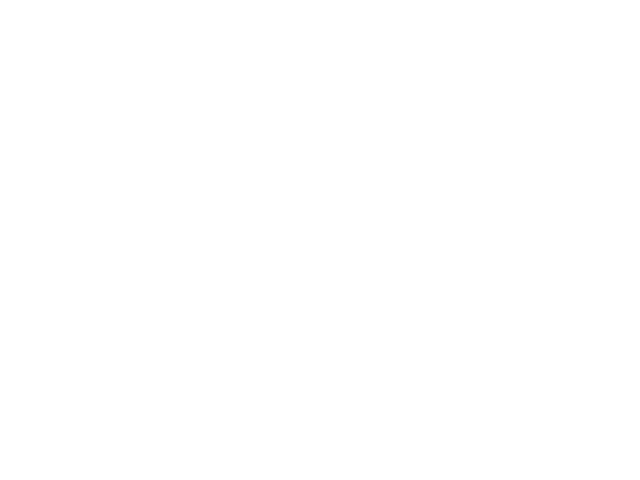

In [36]:
def rollout_sys_to_guard(xm):
    xp = sys.reset(0, xm)
    traj = diffeqsolve(term, solver, t0=0, t1=2, dt0=0.001, y0=xp, args=u, event=event, saveat=SaveAt(steps=1), throw=False, max_steps=8192)
    ts = traj.ts
    ys = traj.ys

    return traj, ts[jnp.isfinite(ts)], ys[jnp.isfinite(ts), :]
plt.figure(1)
plt.clf()
a = guard_pts_to_full(guard_pts)
for i in range(0, N, 50):
    x0_pt = a[:, i].T
    # print(x0_pt)
    sol, ts, ys = rollout_sys_to_guard(x0_pt)
    if(sol.result != RESULTS.event_occurred):
        print(sol.result)
        plt.scatter(ys[0, 0], ys[0, 1])
        plt.plot(ys[:, 0], ys[:, 1])
        print(guard_vmap(ys[-1, :][np.newaxis, :]))
        x_guard = np.linspace(np.min(ys[:, 0]), np.max(ys[:, 0]), 200)
        plt.plot(x_guard, 2 * sys.gamma - x_guard, 'k:')
        # plt.plot(ys[:, 1], ys[:, 3])

plt.show()
plt.close()

In [67]:
## Algorithm subroutines for working with Ellipsoids

def sample_from(e: Ellipsoid, N_pts: int) -> np.ndarray:
    # Sample Normal Distribution 
    # TODO: pull dimension of ellipsoid
    d = len(e.c)
    pts = np.random.standard_normal((d, N_pts))
    r = np.random.uniform(0, 1, size=(N,)) ** (1/d) # The denominator of the power is also the dimension
    pts = r*pts/np.linalg.vector_norm(pts, axis=0)
    return np.linalg.inv(sqrtm(e.Q))@pts + e.c
    

def reject_and_resample(Ei: Ellipsoid, I, Pxi, rescale=0.99, rescale_strategy = 'const') -> Tuple[np.ndarray, Ellipsoid, np.ndarray]:
    N = Pxi.shape[1]
    in_idx = Ei.contains_point(Pxi)
    in_pts = I[:, in_idx]
    out_pts = I[:, ~in_idx]
    Ein = Ellipsoid(Pxi.shape[0])
    all_pts = np.hstack((in_pts, Pxi[:, Ei.contains_point(Pxi)]))
    if(all_pts.shape[1] == 0):
        all_pts = Pxi
    Ein.fit_p_ball(all_pts.T, 2)
    if rescale_strategy == 'const':
        Ein.scale(rescale) # Enforce contraction rate
    elif rescale_strategy == 'iter':
        while any(Ein.contains_point(out_pts)):
            Ein.scale(rescale) # Enforce contraction rate

    return sample_from(Ein, N), Ein, all_pts

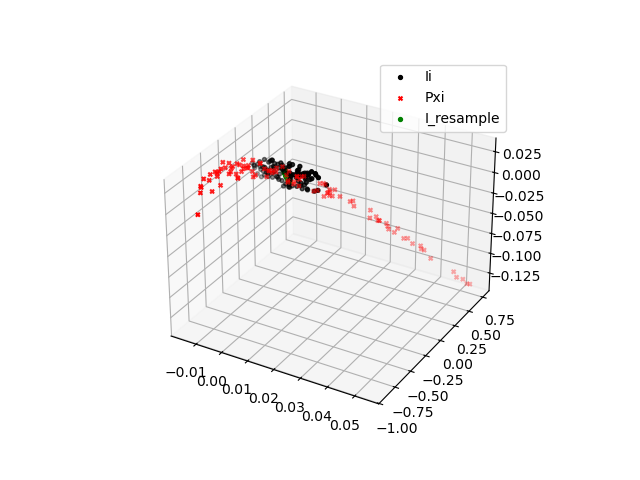

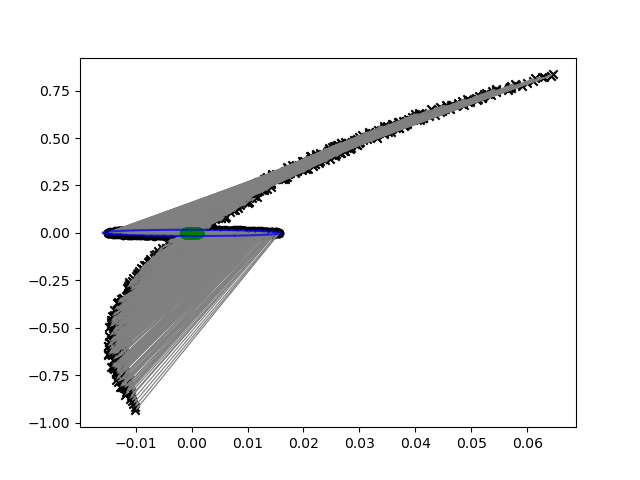

In [64]:
# Test Sampling from Ellipsoid 
# E4 = Ellipsoid(4)
# alpha = np.array([[165.28081557, 113.26623346,  -4.54506446,  36.16299909],
#        [113.26623346, 485.24903395, -29.07552002, 158.31441697],
#        [ -4.54506446, -29.07552002,  29.20983934, -10.56800326],
#        [ 36.16299909, 158.31441697, -10.56800326,  83.72457104]]) 
# E4.Q = alpha.T@alpha
# E4.c = np.array([[ 0.323636  , -0.21863605,  0.37208375,  1.0906425 ]]).T
# full_pts = sample_from(E4, N)
# print(full_pts.shape)

# guard_pts = full_pts_to_guard(full_pts)

E0 = Ellipsoid(3)
E0.fit_p_ball(guard_pts.T, 2)

# Test sample_from
Ii = sample_from(E0, N)
Ei = E0
Ii_full = guard_pts_to_full(Ii)
# fig, ax = plt.subplots()
# ax.scatter(Ii[2, :], Ii[3, :])
# plt.show()

# Test reject_and_resample
Pxi_full = P(Ii_full.T).T
Pxi = full_pts_to_guard(Pxi_full)

assert jnp.allclose(guard_vmap(Ii_full.T), 0, atol=5e-7)
assert jnp.allclose(guard_vmap(Pxi_full.T), 0, atol=5e-7)

assert Ii.shape == (3, N)
assert Pxi.shape == (3, N)

# P(in_pts) should lie completely within E0
# We want E_resample to tightly wrap in_pts
# P(I_resample) should also lie within E0
I_resample, E_resample, in_pts = reject_and_resample(E0, Ii, Pxi, rescale=0.99, rescale_strategy='iter')

# Pin_points = P(guard_pts_to_full(in_pts).T).T


# Px_resample = P(guard_pts_to_full(I_resample).T).T
fig1, ax1 = plt.subplots()
inds = [0, 1]
ax1.scatter(Ii[inds[0], :], Ii[inds[1], :], c='black', marker='o', label='Ii')
ax1.scatter(Pxi[inds[0], :], Pxi[inds[1], :], c='black', marker='x', label='Pxi')
ax1.quiver(
    Ii[inds[0], :],  # X
    Ii[inds[1], :],  # Y
    Pxi[inds[0], :]-Ii[inds[0], :],  # U
    Pxi[inds[1], :]-Ii[inds[1], :],  # V
    angles='xy', 
    scale_units='xy',
    scale=1,
    color='gray'
    )
ax1.scatter(I_resample[inds[0], :], I_resample[inds[1], :], c='green', marker='o', label='I_resample')
# ax1.scatter(in_pts[0, :], in_pts[1, :], c='blue', marker='o', label='in_pts')
# ax1.legend()
plot_projection(E0.Q, E0.c.flatten(), 1, ax1, color = 'blue', diml = inds[0], dimh=inds[1])
plot_projection(E_resample.Q, E_resample.c.flatten(), 1, ax1, color = 'green', diml = inds[0], dimh=inds[1])

fig2 = plt.figure()
fig2.clf()
ax2 = fig2.add_subplot(111, projection='3d')

ax2.scatter(Ii[0, ::10], Ii[1, ::10], Ii[2, ::10], c='black', marker='o', s=8, label='Ii')
ax2.scatter(Pxi[0, ::10], Pxi[1, ::10], Pxi[2, ::10], c='red', marker='x', s=8, label='Pxi')
ax2.scatter(I_resample[0, ::10], I_resample[1, ::10], I_resample[2, ::10], c='green', marker='o', s=8, label='I_resample')

# ax2.set_xlabel('dim 0')
# ax2.set_ylabel('dim 1')
# ax2.set_zlabel('dim 2')
ax2.legend()
plt.show()

# ax2.scatter(Ii_guard[1, :], Ii_guard[2, :], c='black', marker='o')
# ax2.scatter(Pxi_guard[1, :], Pxi_guard[2, :], c='black', marker='x')
# ax2.scatter(I_resample[1, :], I_resample[2, :], c='green', marker='o')
# ax2.scatter(in_pts[1, :], in_pts[2, :], c='blue', marker='o')
# plot_ellipse(E0.Q, E0.c.flatten(), 1, ax2, diml=1, dimh=2, color = 'blue')
# plot_ellipse(E_resample.Q, E_resample.c.flatten(), 1, ax2, diml=1, dimh=2, color = 'green')

# print(E0.Q)
# print(E0.c)
# print(E_resample.Q)
# print(E_resample.c)


0
[[ 6.34902540e+05 -7.84675317e+03  2.04449111e+05]
 [-7.84675317e+03  9.96404829e+01 -2.50774945e+03]
 [ 2.04449111e+05 -2.50774945e+03  6.60293066e+04]] [[ 0.01675482]
 [ 0.01036821]
 [-0.05085858]]


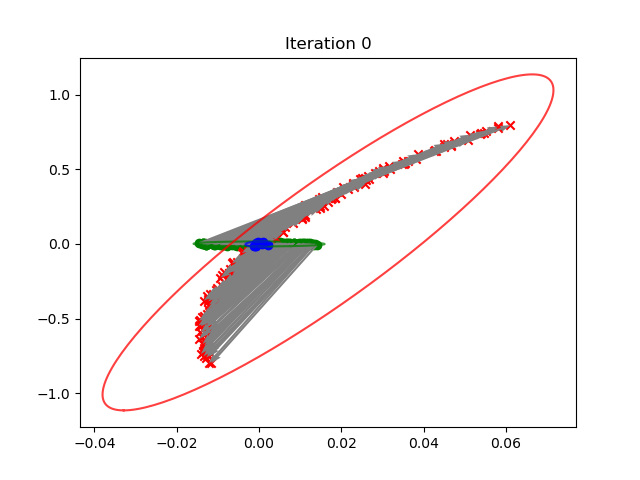

1
[[ 1.61473078e+09 -3.25186836e+07  4.02739218e+08]
 [-3.25186836e+07  6.55013832e+05 -8.11069472e+06]
 [ 4.02739218e+08 -8.11069472e+06  1.00457556e+08]] [[ 9.52976191e-05]
 [ 3.22353816e-03]
 [-6.78360431e-05]]


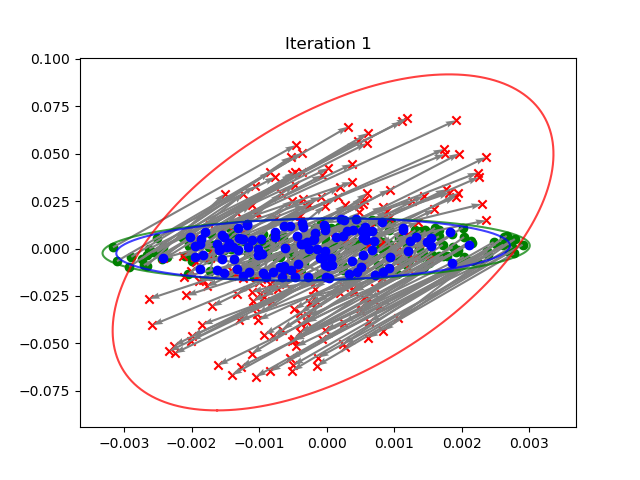

2
[[ 1.36550005e+09 -2.75924838e+07  3.40279209e+08]
 [-2.75924838e+07  5.57691330e+05 -6.87605752e+06]
 [ 3.40279209e+08 -6.87605752e+06  8.48009122e+07]] [[-5.88451720e-05]
 [ 1.19053158e-02]
 [ 1.24763983e-03]]


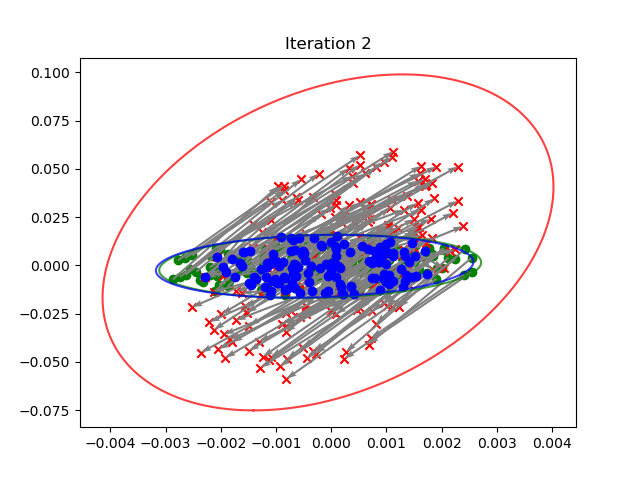

3
[[ 2.22226831e+09 -4.48336565e+07  5.53739919e+08]
 [-4.48336565e+07  9.04749916e+05 -1.11717568e+07]
 [ 5.53739919e+08 -1.11717568e+07  1.37994089e+08]] [[-5.80651043e-05]
 [ 3.01382206e-03]
 [ 5.12321734e-04]]


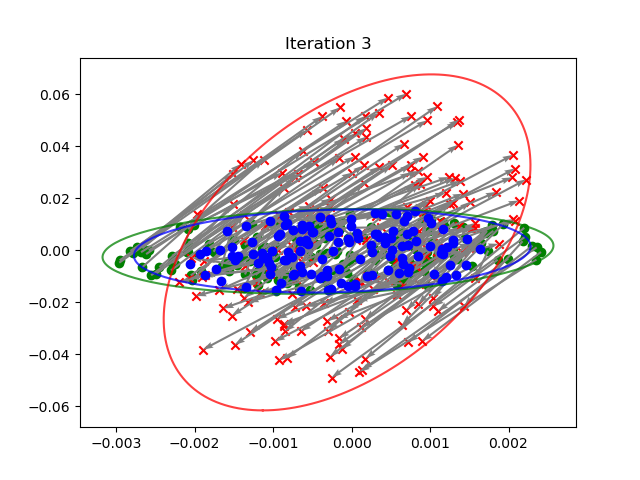

4
[[ 1.50841691e+13 -3.03753177e+11  3.75500792e+12]
 [-3.03753177e+11  6.11674343e+09 -7.56154068e+10]
 [ 3.75500792e+12 -7.56154068e+10  9.34760435e+11]] [[-6.67005029e-05]
 [-1.91148759e-02]
 [-1.25627463e-03]]


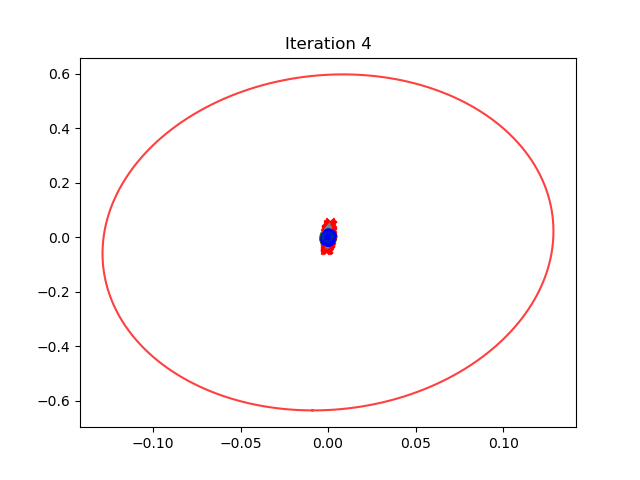

5
[[ 6.60952309e+08 -1.33000221e+07  1.64235567e+08]
 [-1.33000221e+07  2.67784355e+05 -3.30483362e+06]
 [ 1.64235567e+08 -3.30483362e+06  4.08098910e+07]] [[ 0.00087072]
 [ 0.00357613]
 [-0.00321143]]


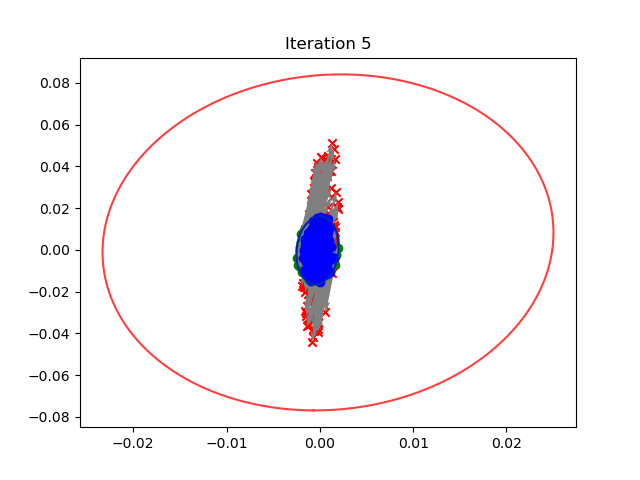

6
[[ 3.82582592e+10 -7.71256297e+08  9.52599957e+09]
 [-7.71256297e+08  1.55479181e+07 -1.92036630e+08]
 [ 9.52599957e+09 -1.92036630e+08  2.37189746e+09]] [[-0.01245854]
 [ 0.07136945]
 [ 0.05583024]]


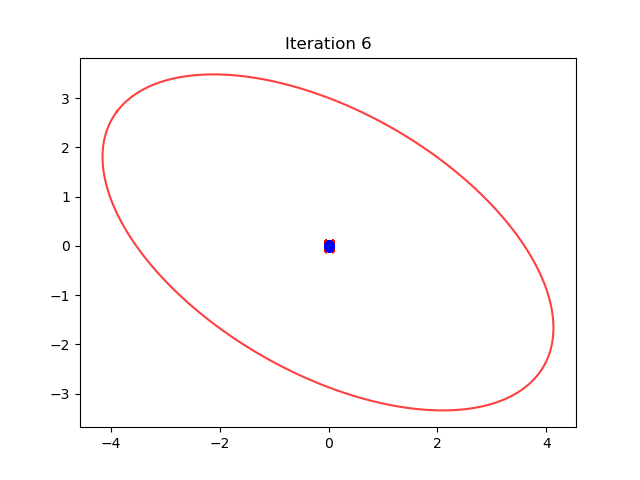

7
[[ 5.93323915e+09 -1.19682935e+08  1.47520926e+09]
 [-1.19682935e+08  2.41424123e+06 -2.97573351e+07]
 [ 1.47520926e+09 -2.97573351e+07  3.66788242e+08]] [[-0.01610903]
 [ 0.00314402]
 [ 0.06505975]]


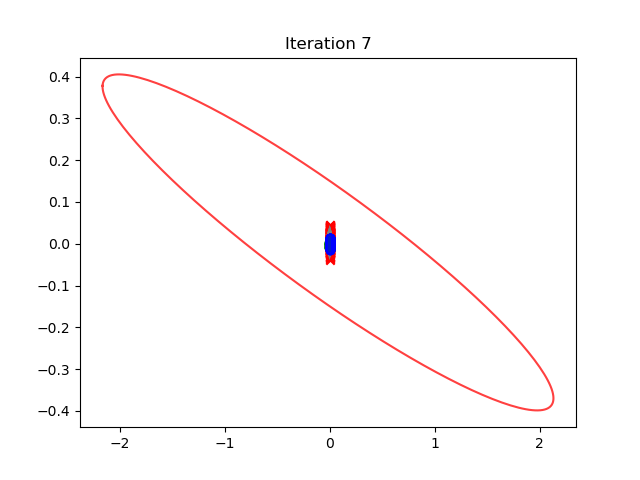

8
[[ 5.35395610e+13 -1.07604243e+12  1.33449907e+13]
 [-1.07604243e+12  2.16263877e+10 -2.68208702e+11]
 [ 1.33449907e+13 -2.68208702e+11  3.32630252e+12]] [[-0.00953628]
 [ 0.01742358]
 [ 0.03968216]]


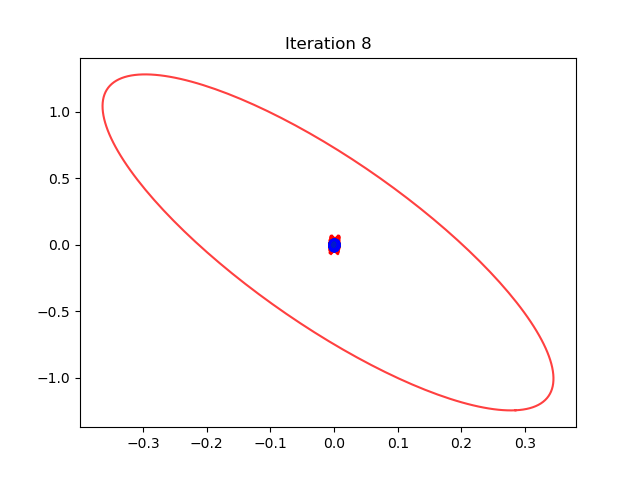

9
[[ 1.28047172e+09 -2.58518892e+07  3.18717855e+08]
 [-2.58518892e+07  5.22517607e+05 -6.43491539e+06]
 [ 3.18717855e+08 -6.43491539e+06  7.93589877e+07]] [[-5.36558238e-05]
 [ 4.23557379e-03]
 [ 5.89320721e-04]]


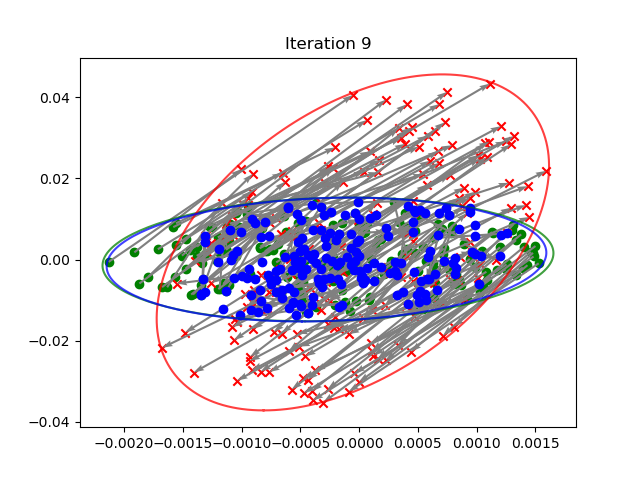

In [69]:
E0 = Ellipsoid(3)
E0.fit_p_ball(guard_pts.T, 2)

Ii = sample_from(E0, N)
Ei = E0
Ii_full = guard_pts_to_full(Ii)

PLOT_EVERY = 5
MAX_ITER = 10

for i in range(MAX_ITER):
    fig, ax = plt.subplots()
    # Compute PXi = P(Ii)
    Ii_full = guard_pts_to_full(Ii)
    Pxi_full = P(Ii_full.T).T
    Pxi = full_pts_to_guard(Pxi_full)

    # If E(PXi) within E(Ii)
    Epxi = Ellipsoid(3)
    Epxi.fit_p_ball(Pxi.T, 2)
    print(i)
    print(Epxi.Q, Epxi.c)
    if(PLOT):
        ax.scatter(Ii[0, ::PLOT_EVERY], Ii[1, ::PLOT_EVERY], c='green', marker='o', label="Ii")
        ax.scatter(Pxi[0, ::PLOT_EVERY], Pxi[1, ::PLOT_EVERY], c='red', marker='x', label="Pxi")
        ax.quiver(
            Ii[0, ::PLOT_EVERY],  # X
            Ii[1, ::PLOT_EVERY],  # Y
            Pxi[0, ::PLOT_EVERY]-Ii[0, ::PLOT_EVERY],  # U
            Pxi[1, ::PLOT_EVERY]-Ii[1, ::PLOT_EVERY],  # V
            angles='xy', 
            scale_units='xy',
            scale=1,
            color='gray'
            )
        plot_projection(Ei.Q, Ei.c.flatten(), 1, ax, color = 'green')
        plot_projection(Epxi.Q, Epxi.c.flatten(), 1, ax, color = 'red')
    if(Ei.contains_ellipsoid(Epxi)):
        print(f"Success! Found Ellipse after {i} iterations:")
        print(f"Q: {Epxi.Q}, c: {Epxi.c}")
        break
    else:
        Ii, Ei, in_pts = reject_and_resample(Ei, Ii, Pxi, rescale=0.99, rescale_strategy='const')

    if(PLOT):
        plt.title(f"Iteration {i}")
        plot_projection(Ei.Q, Ei.c.flatten(), 1, ax, color = 'blue')
        # ax.scatter(Ii[0, ::PLOT_EVERY], Ii[1, ::PLOT_EVERY], c='blue', marker='o', label="resampled")
        ax.scatter(in_pts[0, ::PLOT_EVERY], in_pts[1, ::PLOT_EVERY], c='blue', marker='o', label="resampled")
        plt.show()



diffrax._solution.RESULTS<>
[14.945791]
diffrax._solution.RESULTS<Terminating differential equation solve because an event occurred.>
[-7.450581e-09]
diffrax._solution.RESULTS<>
[14.782408]
diffrax._solution.RESULTS<>
[14.973377]
diffrax._solution.RESULTS<>
[15.099022]
diffrax._solution.RESULTS<>
[15.130884]
diffrax._solution.RESULTS<Terminating differential equation solve because an event occurred.>
[-2.2351742e-08]
diffrax._solution.RESULTS<>
[15.272586]
diffrax._solution.RESULTS<Terminating differential equation solve because an event occurred.>
[7.450581e-09]
diffrax._solution.RESULTS<>
[14.67798]
diffrax._solution.RESULTS<>
[14.735758]
diffrax._solution.RESULTS<Terminating differential equation solve because an event occurred.>
[-7.450581e-09]
diffrax._solution.RESULTS<Terminating differential equation solve because an event occurred.>
[7.450581e-09]
diffrax._solution.RESULTS<Terminating differential equation solve because an event occurred.>
[2.2351742e-08]
diffrax._solution.RESU

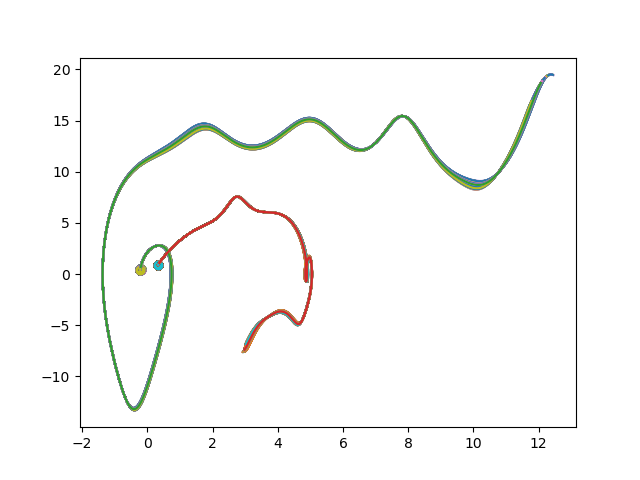

In [ ]:
plt.figure(3)
plt.clf()
pts_final_full = sample_from(E4, N)
# pts_final_full = guard_pts_to_full(pts_final)

for i in range(0, N, 10):
    x0_pt = pts_final_full[:, i].T
    # print(x0_pt)
    sol, ts, ys = rollout_sys_to_guard(x0_pt)
    print(sol.result)
    plt.scatter(ys[0, 0], ys[0, 2])
    plt.scatter(ys[0, 1], ys[0, 3])
    plt.plot(ys[:, 0], ys[:, 2])
    plt.plot(ys[:, 1], ys[:, 3])
    print(guard_vmap(ys[-1, :][np.newaxis, :]))
    # x_guard = np.linspace(np.min(ys[:, 0]), np.max(ys[:, 0]), 200)
    # plt.plot(x_guard, 2 * sys.gamma - x_guard, 'k:')

plt.show()
# plt.close()